In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

data_dir = Path(r".")

### 2a

In [2]:
anchors = np.loadtxt(data_dir / "anchorsII.dat")
ranges = np.loadtxt(data_dir / "rangesII.dat")
r_first = ranges[0]  # 第 t=1 个时刻的三个测距

for j, point in enumerate(anchors, start=1):
    u = point - anchors             # 三行分别是 p - s_i
    q = np.sum(u**2, axis=1) - r_first**2

    H = 2 * u.T @ u + q.sum() * np.eye(2)

    print(f"\nHessian at anchor {j}:")
    print(H)
    print("Eigenvalues:", np.linalg.eigvalsh(H))


Hessian at anchor 1:
[[263.69281078   4.        ]
 [  4.          14.01281078]]
Eigenvalues: [ 13.94874519 263.75687636]

Hessian at anchor 2:
[[ 3.88528108e+01 -2.22044605e-16]
 [-2.22044605e-16 -6.05071892e+01]]
Eigenvalues: [-60.50718922  38.85281078]

Hessian at anchor 3:
[[263.69281078  -4.        ]
 [ -4.          14.01281078]]
Eigenvalues: [ 13.94874519 263.75687636]


### 1c

In [3]:
import numpy as np
import matplotlib.pyplot as plt

anchors = np.loadtxt(data_dir / "anchorsII.dat")
ranges = np.loadtxt(data_dir / "rangesII.dat")
checkpoints = np.loadtxt(data_dir / "checkpointsII.dat")

T = ranges.shape[0]
C = 2 * (anchors[1:] - anchors[0])
anchor_norms_squared = np.sum(anchors**2, axis=1)

P_lls = np.empty((T, 2))

for t in range(T):
    d_t = (
        ranges[t, 0]**2 - ranges[t, 1:]**2
        + anchor_norms_squared[1:] - anchor_norms_squared[0]
    )
    P_lls[t] = np.linalg.solve(C.T @ C, C.T @ d_t)

print("C =")
print(C)

C =
[[10.   0.8]
 [20.   0. ]]


In [9]:
def range_gradient(p, r_t):
    u = p - anchors
    residuals = np.sum(u**2, axis=1) - r_t**2
    return np.sum(residuals[:, None] * u, axis=0)


static_step = 1e-3
static_tol = 1e-8
max_static_updates = 100_000

P_gd = np.empty_like(P_lls)
iterations_static = np.empty(T, dtype=int)

for t in range(T):
    p = P_lls[t].copy()

    for k in range(max_static_updates + 1):
        grad = range_gradient(p, ranges[t])

        if np.linalg.norm(grad) <= static_tol:
            break

        if k == max_static_updates:
            raise RuntimeError(f"Iteration limit reached at time {t + 1}")

        p = p - static_step * grad

    P_gd[t] = p
    iterations_static[t] = k

print("Smallest iteration count:", iterations_static.min())
print("Largest iteration count:", iterations_static.max())

Smallest iteration count: 344
Largest iteration count: 59531


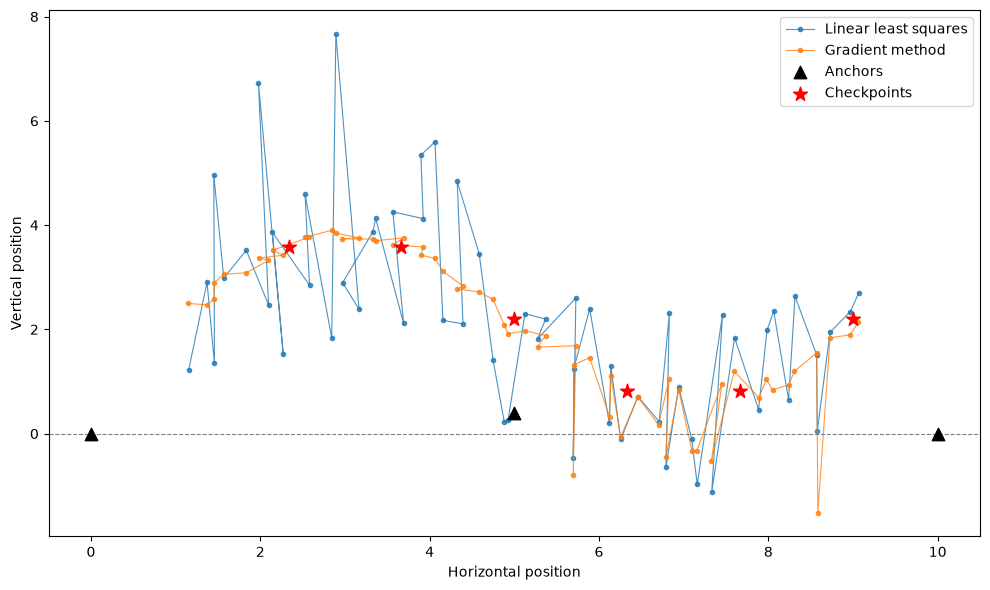

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(P_lls[:, 0], P_lls[:, 1], "o-",
        markersize=3, linewidth=0.8, alpha=0.8,
        label="Linear least squares")
ax.plot(P_gd[:, 0], P_gd[:, 1], "o-",
        markersize=3, linewidth=0.8, alpha=0.8,
        label="Gradient method")

ax.scatter(anchors[:, 0], anchors[:, 1],
           marker="^", s=80, color="black",
           label="Anchors", zorder=4)
ax.scatter(checkpoints[:, 1], checkpoints[:, 2],
           marker="*", s=110, color="red",
           label="Checkpoints", zorder=5)

ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
ax.set(xlabel="Horizontal position", ylabel="Vertical position")
ax.set_aspect("auto")
ax.legend()
fig.tight_layout()
fig.savefig("./figures/2c_1.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
checkpoint_idx = checkpoints[:, 0].astype(int) - 1
true_positions = checkpoints[:, 1:]


def checkpoint_error(P):
    errors = P[checkpoint_idx] - true_positions
    return np.sqrt(np.mean(np.sum(errors**2, axis=1)))


print(f"LLS checkpoint error = {checkpoint_error(P_lls):.8f}")
print(f"GD checkpoint error  = {checkpoint_error(P_gd):.8f}")

LLS checkpoint error = 1.03870594
GD checkpoint error  = 0.42534259


In [12]:
eigenvalues = np.linalg.eigvalsh(C.T @ C)
kappa_C = eigenvalues[-1] / eigenvalues[0]

print(f"lambda_min = {eigenvalues[0]:.8f}")
print(f"lambda_max = {eigenvalues[-1]:.8f}")
print(f"kappa(C.T @ C) = {kappa_C:.8f}")

lambda_min = 0.51186883
lambda_max = 500.12813117
kappa(C.T @ C) = 977.06307652


In [8]:
jump_idx = np.flatnonzero(P_gd[:-1, 1] * P_gd[1:, 1] < 0)

print("Jump pairs (previous time, arrival time):")
for i in jump_idx:
    print((i + 1, i + 2))

print("Arrival times:", (jump_idx + 2).tolist())

Jump pairs (previous time, arrival time):
(np.int64(34), np.int64(35))
(np.int64(35), np.int64(36))
(np.int64(39), np.int64(40))
(np.int64(40), np.int64(41))
(np.int64(43), np.int64(44))
(np.int64(44), np.int64(45))
(np.int64(45), np.int64(46))
(np.int64(47), np.int64(48))
(np.int64(48), np.int64(49))
(np.int64(49), np.int64(50))
(np.int64(56), np.int64(57))
(np.int64(57), np.int64(58))
Arrival times: [35, 36, 40, 41, 44, 45, 46, 48, 49, 50, 57, 58]
